Acá deberíamos armar el primer ejemplo principal que condense todo y quede bien presentado.
Sugiero tomar el caso del agua y armar:

* Curva de equilibrio líquido-vapor
* Definir un rango de presión y temperatura acorde y evaluar las propiedades del vapor en esa región.
* Crear gráficos de T vs h a p constante (serían datos muy directos de obtener)

Hacer lo anterior para la web y con uno de los paquetes. Graficar ambos resultados en simultáneo

Corregir para que no interpole los valores dentro de la campana

# Ejemplo de comparación para el agua
Se obtienen los datos de equilibrio líquido-vapor y de vapor sobrecalentado para el agua, tanto mediante la búsqueda web en NIST como mediante el paquete CoolProp.

## Importación y definición de rango de interés

In [ ]:
from thermo_pkg_nist_compare import busqueda_web_nist
from thermo_pkg_nist_compare import graficar
from thermo_pkg_nist_compare import PropData
from thermo_pkg_nist_compare import Substance
from thermo_pkg_nist_compare.datos_nist_web import ALIAS_BASE, UNIDADES_VALIDAS

import CoolProp.CoolProp as CP
import numpy as np

print("listado de unidades disponibles")
for var, unidad in UNIDADES_VALIDAS.items():
    print(f"{var}: {unidad}")

s = Substance.from_alias("agua")

# CoolProp trabaja en Pa, lo pasamos a bar.
# Con s.english = "water", CoolProp utilizará IAWPS95
model_disp = {"IAPWS95": "Water", "IAPWS-97": "IF97::Water"}

T_crit = CP.PropsSI('Tcrit', s.english)           # K
P_crit = CP.PropsSI('pcrit', s.english)/1e5       # bar
T_triple = CP.PropsSI('Ttriple', s.english)       # K
P_triple = CP.PropsSI('ptriple', s.english)/1e5   # bar

print("\n"+"-"*79)
print(f"Sustancia: {s.spanish}")
print(f"  Punto triple:\n    T = {T_triple:.2f} K\n    P = {P_triple:.2f} bar")
print(f"  Punto crítico:\n    T = {T_crit:.2f} K\n    P = {P_crit:.2f} bar")

Tmin = T_triple+0.1    # K
Tmax = T_crit-0.1      # K
Pmin = P_triple        # bar
Pmax = P_crit          # bar

num_pointsP = 11
num_pointsT = 101
deltaT = (Tmax-Tmin)/num_pointsT

P_iso_graf = np.linspace(Pmin+0.5,Pmax-10,num_pointsP)

listado de unidades disponibles
TUnit: ('K', 'ºC', 'ºF', 'R')
PUnit: ('MPa', 'bar', 'atm', 'torr', 'psia')
DUnit: ('kg/m3', 'mol/l', 'mol/m3', 'g/l', 'lb-mole/ft3', 'lbm/ft3')
HUnit: ('kJ/mol', 'kJ/kg', 'kcal/mol', 'Btu/lb-mol', 'kcal/g', 'Btu/lbm')
WUnit: ('m/s', 'ft/s', 'mph')
VisUnit: ('uPa*s', 'Pa*s', 'cP', 'lbm/ft*s')
STUnit: ('N/m', 'dyn/cm', 'lb/ft', 'lb/in')

-------------------------------------------------------------------------------
Sustancia: Agua
  Punto triple:
    T = 273.16 K
    P = 0.01 bar
  Punto crítico:
    T = 647.10 K
    P = 220.64 bar


## Búsqueda web: datos de saturación

In [ ]:
tabla_liq, tabla_vap = busqueda_web_nist(
    tipo_busq="SatP",
    iso_value=None,
    rg_min=Tmin,
    rg_max=Tmax,
    rg_interval=deltaT,
    unidades = {
        "TUnit": "K",
        "PUnit": "bar",
        "HUnit": "kJ/kg",
        "DUnit": "kg/m3",
        },
)

# # Nos quedamos solo con los datos de interés:
# tabla_liq = tabla_liq[["T", "P", "u", "h", "s", "ph"]]
# tabla_vap = tabla_vap[["T", "P", "u", "h", "s", "ph"]]

# Extractamos específicamente los datos de T_sat, hv_sat y hL_sat y construímos
# un solo juego de datos representando la "campana"
T_sat_web = np.concatenate((tabla_liq["T"], np.flip(tabla_liq["T"])))
h_sat_web = np.concatenate((tabla_liq["h"], np.flip(tabla_vap["h"])))

## Búsqueda web: datos de vapor sobrecalentado a diferentes presiones

In [21]:
datos_vsc_web = []

T_sat_interp = np.interp(P_iso_graf, tabla_vap["P"], tabla_liq["T"])

for Tini, P_iso in zip(T_sat_interp, P_iso_graf):
    dT = (Tmax - Tini) / num_pointsT

    datos_vsc_web.append(
        busqueda_web_nist(
            tipo_busq="IsoBar",
            iso_value=P_iso,
            rg_min=Tini,
            rg_max=T_crit,
            rg_interval=dT,
            unidades={
                "PUnit": "bar",
                "HUnit": "kJ/kg",
                "Tunidades": "K",
                "DUnit": "kg/m3",
            },
        )[["T", "P", "h"]]
    )



## Cálculo empleando CoolProp: datos de saturación

In [13]:
# Con s.english = "water", CoolProp utilizará IAWPS95
T_sat_cp_simple = CP.PropsSI("T", "P", tabla_vap["P"]*1e5 , "Q", 1, s.english)

hL_sat_cp = CP.PropsSI("Hmass", "P", tabla_vap["P"]*1e5 , "Q", 0, s.english)
hv_sat_cp = CP.PropsSI("Hmass", "P", tabla_vap["P"]*1e5 , "Q", 1, s.english)

# Extractamos específicamente los datos de T_sat, hv_sat y hL_sat y construímos
# un solo juego de datos representando la "campana"
T_sat_cp = np.concatenate((T_sat_cp_simple, np.flip(T_sat_cp_simple)))
h_sat_cp = np.concatenate((hL_sat_cp, np.flip(hv_sat_cp)))

## Cálculo empleando CoolProp: datos de vapor sobrecalentado a diferentes presiones

In [20]:
encabezados = ["T", "P", "h"]
unidades = {"T": "K", "P": "bar", "h" : "kJ/kg"}

# Con s.english = "water", CoolProp utilizará IAWPS95
datos_vsc_cp = []


T_sat_interp = np.interp(P_iso_graf, tabla_vap["P"], T_sat_cp_simple)

for Tini, P_iso in zip(T_sat_interp, P_iso_graf*1e5):
    T = np.linspace(Tini, Tmax, num_pointsT)
    P = np.ones((num_pointsT, 1))*P_iso
    h_cp = CP.PropsSI("Hmass", "P", P_iso, "T", T, s.english)/1000  # kJ/kg
    
    tabla_array = np.column_stack((T, P/1e5, h_cp))

    datos_vsc_cp.append(
        PropData(datos=tabla_array,
                 encabezados=encabezados,
                 unidades=unidades,
                 alias_base=ALIAS_BASE)
                 )



In [ ]:
"""P_sat = 101325.0  # Pa

T_sat = CP.PropsSI("T", "P", P_sat, "Q", 0, "Water")
h_f = CP.PropsSI("H", "P", P_sat, "Q", 0, "Water")   # Líquido saturado
h_g = CP.PropsSI("H", "P", P_sat, "Q", 1, "Water")   # Vapor saturado
h_fg = h_g - h_f                                  # Calor latente de vaporización

print(f"T_sat: {T_sat:.2f} K ({T_sat - 273.15:.2f} °C)")
print(f"h_f: {h_f/1000:.2f} kJ/kg | h_g: {h_g/1000:.2f} kJ/kg | h_fg: {h_fg/1000:.2f} kJ/kg")
"""

T_sat: 373.12 K (99.97 °C)
h_f: 419.06 kJ/kg | h_g: 2675.53 kJ/kg | h_fg: 2256.47 kJ/kg


## Graficamos la curva Psat-Tsat con el "graficador"

Water
Water
IF97::Water


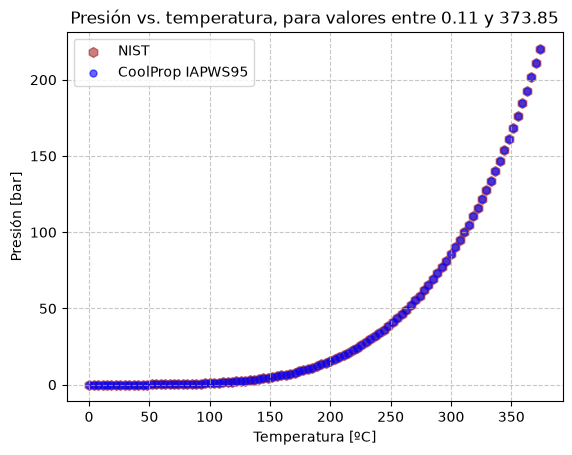

In [10]:
print(s.english)
for k in model_disp:
    print(model_disp[k])

modelo = next((k for k, v in model_disp.items() if s.english.lower()==v.lower()), None)

graficar(
    T_sat_cp_simple-273.15,
    tabla_vap["P"],
    x_comp=tabla_vap["T"]-273.15,
    y_comp=tabla_vap["P"],
    label_2="CoolProp "+modelo,
    nombre_x="Temperatura",
    nombre_y="Presión",
    unidad_x="ºC",
    unidad_y="bar",
    color='brown',
    linewidth=0.7,
    markersize=50,
    interpolar=False)

## Gráfico h-T, incluyendo Eq. líquido-vapor
Debemos crear un gráfico con matplotlib para mayor versatilidad

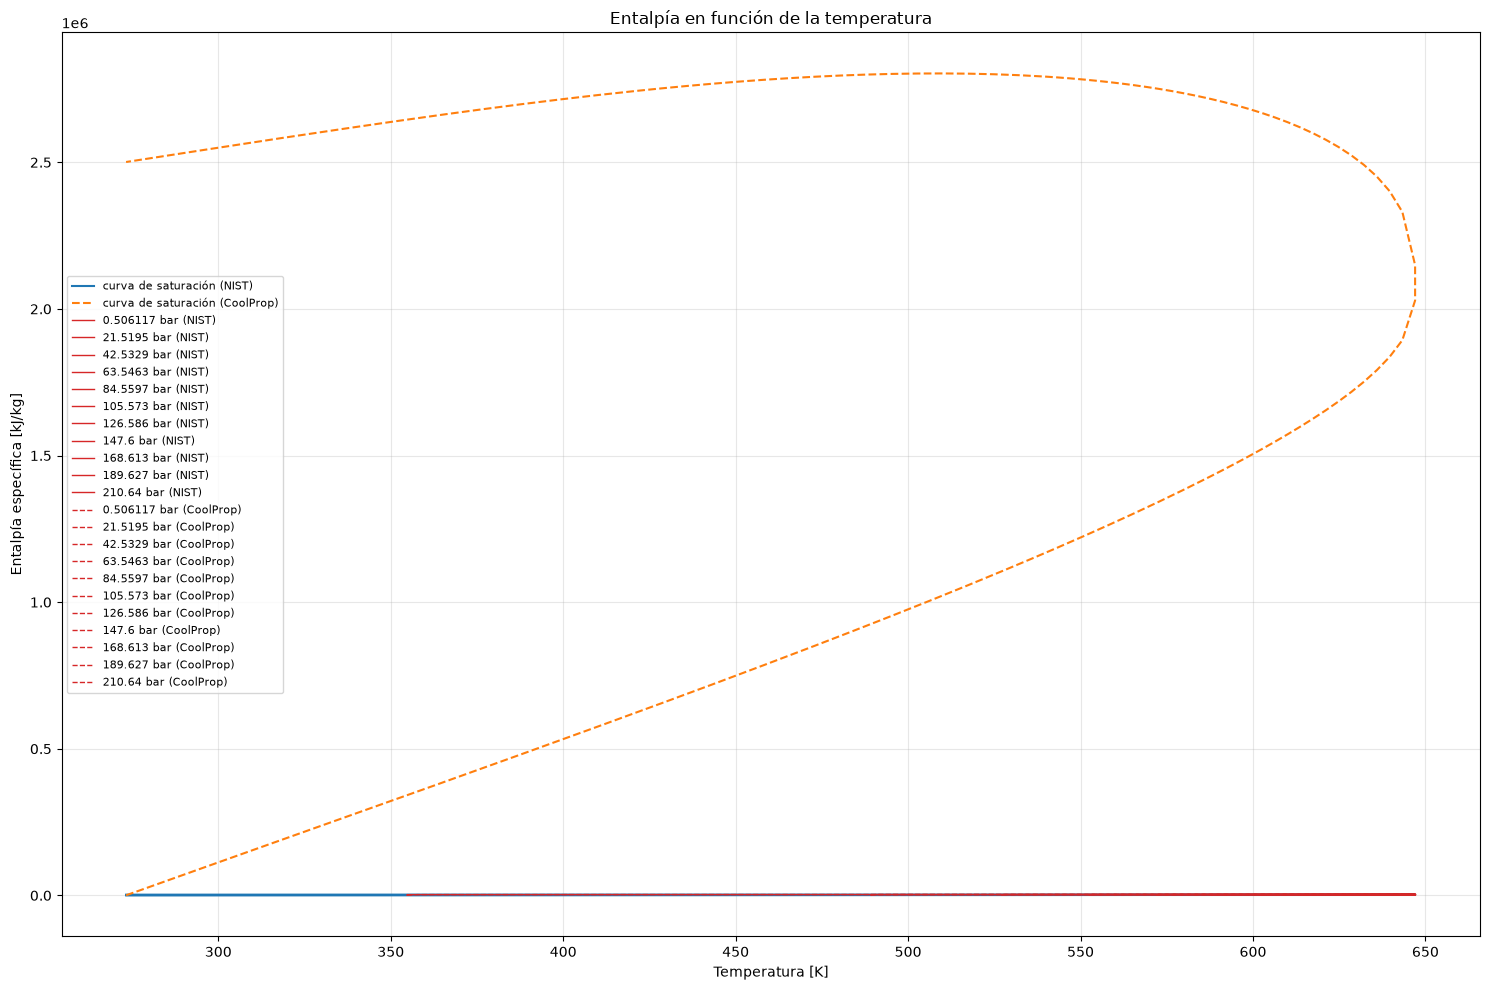

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 10))

# Ordenar por temperatura para que las líneas y el relleno sigan la curva.
ax.plot(
    T_sat_web, h_sat_web, label="curva de saturación (NIST)", color="tab:blue"
    )
ax.fill_between(
    tabla_liq["T"],
    tabla_liq["h"],
    tabla_vap["h"],
    color="tab:blue",
    alpha=0.12
    )

ax.plot(
    T_sat_cp, h_sat_cp,
    "--", label="curva de saturación (CoolProp)", color="tab:orange",
)

# Isobaras de vapor sobrecalentado (NIST)
for isobara in datos_vsc_web:
    ax.plot(
        isobara["T"],
        isobara["h"],
        linewidth=1,
        color="tab:red",
        label=f"{isobara["P"][0]:g} bar (NIST)",
    )

# Isobaras de vapor sobrecalentado (CoolProp)
for isobara in datos_vsc_cp:
    ax.plot(
        isobara["T"],
        isobara["h"],
        "--",
        linewidth=1,
        color="tab:red",
        label=f"{isobara["P"][0]:g} bar (CoolProp)",
    )

ax.set_xlabel("Temperatura [K]")
ax.set_ylabel("Entalpía específica [kJ/kg]")
ax.set_title("Entalpía en función de la temperatura")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()